In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
#from tqdm import tqdm_notebook as tqdm
from tqdm.auto import tqdm
import torch
import time

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

/nfs/home/alifa/myenv/lib/python3.12/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [2]:
# b0 = 1
# b1 = 1
# b2 = 1
# sigma0 = 1
# sigma2 = 1

# params = {'b0': b0, 'b1': b1, 'b2': b2,
#           'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
#           'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
#           'T': 1, 'Nt': 1_000}

with open(f'experiment_params.pkl', 'rb') as f:
    params = pickle.load(f)
    f.close()

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

Simulating HJB control
Time elapsed: 8.169395145 seconds


  0%|          | 0/16 [00:00<?, ?it/s]

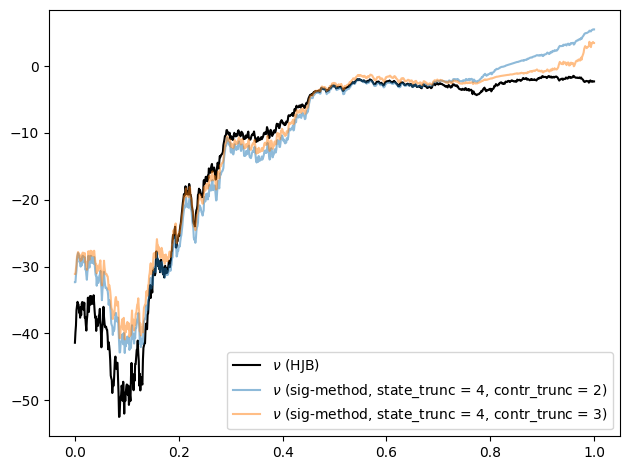

In [3]:
max_order_x_list = [1, 2, 3, 4]
max_order_F_list = [0, 1, 2, 3]
max_max_order_F = max(max_order_F_list)
sim_list = []
dim = env.dim # equals 2
nsims = 1000
nsims_small = nsims
random_seed = 123
nsim = 0  # choose one sample path

# simulate with actual optimal control from HJB
print('Simulating HJB control')
start = time.process_time()
np.random.seed(random_seed)
env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, order = 1, fast = True)  # order doesn't matter for HJB control
print(f'Time elapsed: {time.process_time() - start} seconds')
hjb_performance = env_hjb.performance.mean()
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)', color='black')

with tqdm(total=len(max_order_x_list)*len(max_order_F_list)) as pbar:
    for max_order_x in max_order_x_list:
        for max_order_F in max_order_F_list:
            # if max_order_x == 2 and max_order_F < 2:
            #     pbar.update(1)
            #     continue
            max_order_fn = max(2*max_order_x + 1, 2*max_order_F + 1)
            filename = f'lev_control_{max_order_F}_lev_state_{max_order_x}_analytical'
            max_order_F
            with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
                F = pickle.load(f)
                f.close()
            F = ta.sig_to_tensor(F, env.dim, max_order_F)
            strag_sig = lqproblem.sig_strag_dot(F, order = max_order_F)
            # simulation with signature controls
            np.random.seed(random_seed)
            env.simulate(nsims, strag_sig, max_max_order_F, fast = False)
            if max_order_x >= 4 and max_order_F >= 2:
                plt.plot(env.timesteps, env.nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
                    alpha=0.5)
            nu_rmse = np.sqrt((((env.nu - env_hjb.nu)**2).sum())*env.T/(env.Nt*nsims))
            mean_performance = env.performance.mean()
            sim_inst = {'max_order_x': max_order_x, 
                        'max_order_F': max_order_F, 
                        'nu_sims': env.nu[:,:nsims_small],
                        'performance': mean_performance,
                        'outperformance': mean_performance - hjb_performance,
                        'nu_rmse': nu_rmse}
            sim_list.append(sim_inst)
            pbar.update(1)
        
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
with open(f'experiment_results_{nsims}_sims.pkl', 'wb') as f:
    pickle.dump(sim_list, f)
    f.close()

with open(f'experiment_results_hjb_{nsims}_sims.pkl', 'wb') as f:
    pickle.dump(env_hjb.nu[:, :nsims_small], f)
    f.close()

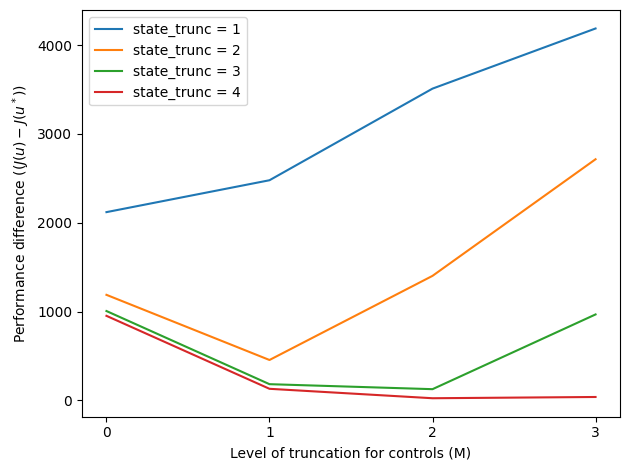

In [8]:
for max_order_x in max_order_x_list:
    perform_diff = [experiment['outperformance'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    plt.plot(max_order_F_list, perform_diff, label=f'state_trunc = {max_order_x}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'Performance difference ($(J(u) - J(u^*)$)')
plt.legend()
plt.tight_layout()
plt.show()
        

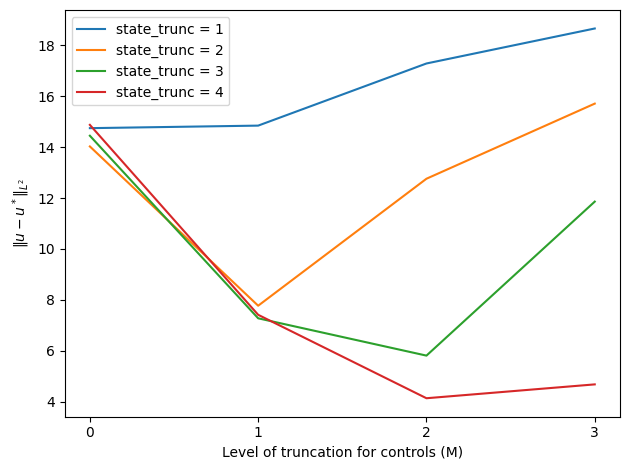

In [6]:
for max_order_x in max_order_x_list:
    perform_diff = [experiment['nu_rmse'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    plt.plot(max_order_F_list, perform_diff, label=f'state_trunc = {max_order_x}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'$\|u - u^*\|_{L^2}$')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
sim_list

[{'max_order_x': 1,
  'max_order_F': 0,
  'nu_sims': array([[-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         ...,
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5]], shape=(1001, 10)),
  'performance': np.float64(2274.786193283372),
  'outperformance': np.float64(1848.3189051229288),
  'nu_rmse': np.float64(13.421800894417617)},
 {'max_order_x': 1,
  'max_order_F': 1,
  'nu_sims': array([[-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.7748    , -16.7748    , -16.7748    , ..., -16.7748    ,
          -16.7748    , -16.7748    ],
         ...,
         [  8.32416666,   